# HealthConnect Rwanda — Week 8: Final Model Selection, Documentation & Presentation
**AnalystLab Africa · Experience Lab · Week 8 · Data Science track**

This notebook closes the Data Science contribution. It does **not** repeat the Week 6 or Week 7 analysis; it reads their saved results and answers the Week 8 tasks:
confirm the final candidate model, compare final performance with the baseline, summarise errors, log modelling decisions, state business suitability (what the model can and cannot be used for),
connect validated Analytics findings to model interpretation, and state the requirements passed to ML Engineering.

**Context carried forward:** the project question is *how HealthConnect can use data and AI to reduce missed appointments*. The project data contain no attendance/no-show field (Week 7 finding I-02), so the tested model predicts **hospital admission**, the Week 6 candidate target.

In [1]:
import json, os, textwrap
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
from scipy import stats
from sklearn.metrics import roc_auc_score

W6 = json.load(open("../outputs/results.json"))["R"]; W7 = json.load(open("../week7/outputs/results.json"))["R"]
OUT = "outputs/"; FIGDIR = OUT + "figures/"; TAB = OUT + "tables/"
for d_ in (FIGDIR, TAB): os.makedirs(d_, exist_ok=True)
R, FIGS, DQ = {}, {}, []
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]; INK, MUTED, GRID, SURF = "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
mpl.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 11})
def save_fig(fig, name, interp, title):
    fig.text(0.01, -0.02, "\n".join(textwrap.wrap("Interpretation: " + interp, 150)), ha="left", va="top", fontsize=8.5, color="#333")
    fig.savefig(FIGDIR + name + ".png", dpi=150, bbox_inches="tight"); FIGS[name] = dict(title=title, interp=interp)
def boot_ci(y, p, n=1000, seed=42):
    r = np.random.default_rng(seed); out = []
    for _ in range(n):
        ix = r.integers(0, len(y), len(y))
        if len(np.unique(y[ix])) == 2: out.append(roc_auc_score(y[ix], p[ix]))
    return float(np.percentile(out, 2.5)), float(np.percentile(out, 97.5))
pd.options.display.float_format = "{:,.3f}".format

## 1. Review of the Week 7 model testing results
Week 7 tested the Week 6 candidate against six acceptance criteria fixed in advance, then tried seven refinements.

In [2]:
HF, CR, IF = W7["holdout_final"], W7["criteria"], W7["interface"]
REV = pd.DataFrame([
    ["Hold-out ROC-AUC (95% CI)", f"{HF['cand']['auc']:.3f} ({HF['cand']['lo']:.2f}–{HF['cand']['hi']:.2f})", "Includes chance (0.50); required ≥ 0.65 with lower bound > 0.50"],
    ["Time-based test AUC (Oct–Dec)", f"{W7['stability']['time_auc']:.3f} (CI {W7['stability']['time_ci'][0]:.2f}–{W7['stability']['time_ci'][1]:.2f})", "No demonstrable skill on future data"],
    ["Share of 30 random splits with AUC > 0.5", f"{W7['stability']['share_above_half']:.0%}", "About what chance gives"],
    ["Calibration slope (ideal 1.0)", f"{W7['calibration']['slope']:.2f}", "Predicted risks are not informative"],
    ["Top-20% rule: precision vs prevalence", f"{W7['capacity_rule']['precision']:.3f} vs 0.117 (lift {W7['capacity_rule']['lift']:.2f}×)", "No enrichment of admissions"],
    ["Acceptance criteria met", f"{CR['passed'][0]} of 6 (candidate); {CR['passed'][1]} of 6 (best refinement)", "Not suitable for patient-level use"],
    ["Best refinement (development CV)", f"{W7['best_refinement']['name']}: ΔAUC {W7['best_refinement']['d']:+.3f}, p = {W7['best_refinement']['p']:.2f}", "Below the +0.02 gain required; not accepted"],
    ["Method validity (planted signals)", f"Detected from true AUC ≈ {W7['min_detectable_auc']:.2f}; shuffled-label AUC {W7['negative_control']['null_mean']:.3f}", "'No signal' reflects the data, not a weak test"],
    ["Scoring-interface tests (Week 6 → refined)", f"{IF['v1_pass']}/{IF['total']} → {IF['v2_pass']}/{IF['total']}", "Interface hardened for ML Engineering"]], columns=["Week 7 result", "Value", "Meaning"])
REV.to_csv(TAB + "w8_week7_review.csv", index=False); REV

,Week 7 result,Value,Meaning
0,Hold-out ROC-AUC (95% CI),0.529 (0.47–0.59),Includes chance (0.50); required ≥ 0.65 with lower bound > 0.50
1,Time-based test AUC (Oct–Dec),0.480 (CI 0.43–0.53),No demonstrable skill on future data
2,Share of 30 random splits with AUC > 0.5,40%,About what chance gives
3,Calibration slope (ideal 1.0),0.18,Predicted risks are not informative
4,Top-20% rule: precision vs prevalence,0.167 vs 0.117 (lift 1.42×),No enrichment of admissions
5,Acceptance criteria met,0 of 6 (candidate); 0 of 6 (best refinement),Not suitable for patient-level use
6,Best refinement (development CV),"R1 Clinical-core features: ΔAUC +0.019, p = 0.13",Below the +0.02 gain required; not accepted
7,Method validity (planted signals),Detected from true AUC ≈ 0.57; shuffled-label AUC 0.501,"'No signal' reflects the data, not a weak test"
8,Scoring-interface tests (Week 6 → refined),8/18 → 18/18,Interface hardened for ML Engineering


## 2. Confirming the final candidate model
Decision rule: choose the option that satisfies the acceptance criteria; if none does, retain the simplest, best-documented model **only as an integration fixture** and state clearly that it is not approved for decisions.

In [3]:
OPT = pd.DataFrame([
    ["Week 6 candidate (logistic regression, 18 booking-time features)", f"{CR['passed'][0]}/6", f"{HF['cand']['auc']:.3f}", "Simplest, reproducible, already wrapped by the validated scorer", "SELECTED as fixture"],
    [f"Best refinement ({HF['ref']['name']})", f"{CR['passed'][1]}/6", f"{HF['ref']['auc']:.3f}", "Not a meaningful gain (ΔAUC +0.008, CI spans 0); fewer features but no better", "Not selected"],
    ["Random forest / gradient boosting (Week 6)", "not run (CV AUC 0.50)", "≈0.50", "Memorises noise (unconstrained forest train AUC 1.00, CV 0.50)", "Rejected"],
    ["Rule-based risk score (RiskScore, no fitting)", "see comparison below", "see comparison below", "Transparent, needs no training data; matches Week 6 recommendation", "Recommended operational tool"]],
    columns=["Option", "Criteria met", "Hold-out AUC", "Reason", "Decision"])
OPT.to_csv(TAB + "w8_final_model_decision.csv", index=False); OPT

,Option,Criteria met,Hold-out AUC,Reason,Decision
0,"Week 6 candidate (logistic regression, 18 booking-time features)",0/6,0.529,"Simplest, reproducible, already wrapped by the validated scorer",SELECTED as fixture
1,Best refinement (R1 Clinical-core features),0/6,0.537,"Not a meaningful gain (ΔAUC +0.008, CI spans 0); fewer features but no better",Not selected
2,Random forest / gradient boosting (Week 6),not run (CV AUC 0.50),≈0.50,"Memorises noise (unconstrained forest train AUC 1.00, CV 0.50)",Rejected
3,"Rule-based risk score (RiskScore, no fitting)",see comparison below,see comparison below,"Transparent, needs no training data; matches Week 6 recommendation",Recommended operational tool


## 3. Final performance against the baseline
Baseline = prior probability (AUC 0.50). The rule-based score has **no fitted parameters**, so it can be evaluated on all 5,000 appointments without leakage (it is descriptive, not tuned). Admission = the target the model was built for.

RiskScore rule on all 5,000 appointments: AUC 0.520 (95% CI 0.495–0.543)
High-risk flag: 33.9% of appointments; admission rate 13.2% vs 11.0% otherwise (chi-square p = 0.022); overall 11.7%


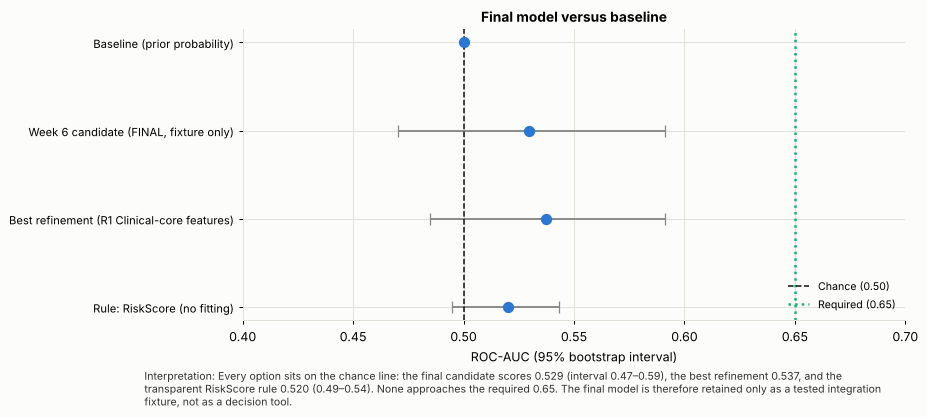

In [4]:
E = pd.read_csv("../outputs/data/HC_Integrated_Encounters_5000.csv", keep_default_na=False, na_values=[""])
y = E.Admitted.values; prev = y.mean()
auc_rule = roc_auc_score(y, E.RiskScore); ci_rule = boot_ci(y, E.RiskScore.values)
hr = E.HighRisk == 1; prec_hr, prec_non = y[hr].mean(), y[~hr].mean(); chi_hr = stats.chi2_contingency(pd.crosstab(E.HighRisk, E.Admitted))[1]
R["rule"] = dict(auc=float(auc_rule), lo=ci_rule[0], hi=ci_rule[1], hr_rate=float(prec_hr), non_rate=float(prec_non), p=float(chi_hr), hr_share=float(hr.mean()), n=len(E), prev=float(prev))
print(f"RiskScore rule on all {len(E):,} appointments: AUC {auc_rule:.3f} (95% CI {ci_rule[0]:.3f}–{ci_rule[1]:.3f})")
print(f"High-risk flag: {hr.mean():.1%} of appointments; admission rate {prec_hr:.1%} vs {prec_non:.1%} otherwise (chi-square p = {chi_hr:.3f}); overall {prev:.1%}")
FINAL = pd.DataFrame([
    ["Baseline (prior probability)", 0.5, 0.5, 0.5, "Hold-out, Week 7"],
    ["Week 6 candidate (FINAL, fixture only)", HF["cand"]["auc"], HF["cand"]["lo"], HF["cand"]["hi"], "Hold-out, Week 7"],
    [f"Best refinement ({HF['ref']['name']})", HF["ref"]["auc"], HF["ref"]["lo"], HF["ref"]["hi"], "Hold-out, Week 7"],
    ["Rule: RiskScore (no fitting)", auc_rule, ci_rule[0], ci_rule[1], "All 5,000 appointments, descriptive"]], columns=["Model", "AUC", "Lo", "Hi", "Evaluated on"])
FINAL.to_csv(TAB + "w8_baseline_vs_final.csv", index=False)
fig, ax = plt.subplots(figsize=(9.5, 4.2)); yy = np.arange(len(FINAL))[::-1]
ax.errorbar(FINAL.AUC, yy, xerr=[FINAL.AUC - FINAL.Lo, FINAL.Hi - FINAL.AUC], fmt="o", color=C[0], ecolor=MUTED, capsize=5, ms=8)
ax.axvline(.5, color=INK, ls="--", lw=1.2, label="Chance (0.50)"); ax.axvline(.65, color=C[2], ls=":", lw=2, label="Required (0.65)")
ax.set_yticks(yy); ax.set_yticklabels(FINAL.Model, fontsize=9); ax.set_xlabel("ROC-AUC (95% bootstrap interval)"); ax.set_xlim(.4, .7); ax.set_title("Final model versus baseline"); ax.legend(frameon=False, fontsize=8.5, loc="lower right")
save_fig(fig, "w8_01_baseline_vs_final", f"Every option sits on the chance line: the final candidate scores {HF['cand']['auc']:.3f} (interval {HF['cand']['lo']:.2f}–{HF['cand']['hi']:.2f}), the best refinement {HF['ref']['auc']:.3f}, and the transparent RiskScore rule {auc_rule:.3f} ({ci_rule[0]:.2f}–{ci_rule[1]:.2f}). None approaches the required 0.65. The final model is therefore retained only as a tested integration fixture, not as a decision tool.", "Final model compared with baseline")
plt.show()

## 4. Error analysis summary and model strengths/weaknesses

In [5]:
EP, CC, FV = W7["error_profile"], W7["conf_counts"], W7["flag_vs_unflag"]
ERRS = pd.DataFrame([
    ["Flagging rule", "Top 20% by score (capacity rule), out-of-fold on all 5,000", ""],
    ["True / false positives", f"{CC['TP']} / {CC['FP']}", f"Precision {CC['TP'] / (CC['TP'] + CC['FP']):.1%} vs prevalence 11.7%"],
    ["False / true negatives", f"{CC['FN']} / {CC['TN']:,}", f"{CC['FN'] / (CC['TP'] + CC['FN']):.0%} of admissions missed"],
    ["Admission rate: flagged vs unflagged", f"{FV['flagged_rate']:.1%} vs {FV['unflagged_rate']:.1%}", f"chi-square p = {FV['p']:.2f}: flags do not enrich for admissions"],
    ["Error pattern", "Flags driven by department, weekday, province categories", "Selection effect; no outcome-related pattern to correct"],
    ["Segments", f"{W7['segments']['n']} assessed; {W7['segments']['holm_sig']} significant after Holm", "No segment where the model works"],
    ["Overfitting", f"Train {W7['overfit'][0]['Train_AUC']:.2f} vs CV {W7['overfit'][0]['CV_AUC']:.2f}", "Mild; learning curve flat at 0.5"]], columns=["Item", "Finding", "Note"])
ERRS.to_csv(TAB + "w8_error_summary.csv", index=False)
SW = pd.DataFrame([
    ["Strengths", "Fully reproducible; transparent (logistic); uses only booking-time fields; validated input/output contract; negative-control and power-tested; model card and caution flag"],
    ["Weaknesses", "No discrimination (AUC ≈ 0.53); uninformative probabilities; flags driven by noise categories; PatientVisits look-ahead; one year of data; wrong target for the project objective (admission, not no-show)"]], columns=["", "Assessment"])
ERRS

,Item,Finding,Note
0,Flagging rule,"Top 20% by score (capacity rule), out-of-fold on all 5,000",
1,True / false positives,127 / 873,Precision 12.7% vs prevalence 11.7%
2,False / true negatives,"459 / 3,541",78% of admissions missed
3,Admission rate: flagged vs unflagged,12.7% vs 11.5%,chi-square p = 0.31: flags do not enrich for admissions
4,Error pattern,"Flags driven by department, weekday, province categories",Selection effect; no outcome-related pattern to correct
5,Segments,34 assessed; 0 significant after Holm,No segment where the model works
6,Overfitting,Train 0.60 vs CV 0.52,Mild; learning curve flat at 0.5


## 5. Modelling decisions log

In [6]:
DEC = pd.DataFrame([
    ["D1", "Week 6", "Target = hospital admission (no attendance field exists)", "Only outcome available that is recorded per appointment", "Wrong target for no-show; flagged as open issue I-02"],
    ["D2", "Week 6", "Exclude diagnosis, severity, labs, prescriptions, referral from the candidate", "Post-visit information: would be leakage at booking time", "Feature set A only"],
    ["D3", "Week 6", "Logistic regression as the candidate; compare with RF and boosting against baselines", "Transparent, strong baseline for weak-signal data", "Flexible models memorised noise"],
    ["D4", "Week 7", "Fix six acceptance criteria before testing", "Prevent the verdict being tuned to the results", "0 of 6 met"],
    ["D5", "Week 7", "Select refinements on development CV only; open hold-out once", "Avoid optimistic bias", "No refinement accepted (needed ΔAUC ≥ 0.02, p < 0.05)"],
    ["D6", "Week 7", "Plant known signals and shuffle labels to test the method", "A 'no signal' verdict needs proof that signal would be seen", "Detected from true AUC ≈ 0.57 upward"],
    ["D7", "Week 7", "Rebuild the scoring interface with a validated contract (V2)", "Interface tests failed 10 of 18 for the Week 6 behaviour", "18/18 pass"],
    ["D8", "Week 8", "Retain the Week 6 candidate unchanged as the FINAL model, as an integration fixture with a caution flag", "No variant met the criteria; simplest documented model", "Not approved for patient-level decisions"],
    ["D9", "Week 8", "Recommend the rule-based risk list and forecasts for operational use", "They need no predictive claim; validated in Week 6", "Used for outreach and slot planning"]], columns=["ID", "Week", "Decision", "Reason", "Outcome"])
DEC.to_csv(TAB + "w8_decision_log.csv", index=False); DEC

,ID,Week,Decision,Reason,Outcome
0,D1,Week 6,Target = hospital admission (no attendance field exists),Only outcome available that is recorded per appointment,Wrong target for no-show; flagged as open issue I-02
1,D2,Week 6,"Exclude diagnosis, severity, labs, prescriptions, referral from the candidate",Post-visit information: would be leakage at booking time,Feature set A only
2,D3,Week 6,Logistic regression as the candidate; compare with RF and boosting against baselines,"Transparent, strong baseline for weak-signal data",Flexible models memorised noise
3,D4,Week 7,Fix six acceptance criteria before testing,Prevent the verdict being tuned to the results,0 of 6 met
4,D5,Week 7,Select refinements on development CV only; open hold-out once,Avoid optimistic bias,"No refinement accepted (needed ΔAUC ≥ 0.02, p < 0.05)"
5,D6,Week 7,Plant known signals and shuffle labels to test the method,A 'no signal' verdict needs proof that signal would be seen,Detected from true AUC ≈ 0.57 upward
6,D7,Week 7,Rebuild the scoring interface with a validated contract (V2),Interface tests failed 10 of 18 for the Week 6 behaviour,18/18 pass
7,D8,Week 8,"Retain the Week 6 candidate unchanged as the FINAL model, as an integration fixture with a caution flag",No variant met the criteria; simplest documented model,Not approved for patient-level decisions
8,D9,Week 8,Recommend the rule-based risk list and forecasts for operational use,They need no predictive claim; validated in Week 6,Used for outreach and slot planning


## 6. Business suitability: what the final model can and cannot be used for
Evidence for the "usable now" column is the Week 6 analysis (own results).

In [7]:
P = pd.read_csv("../outputs/data/HC_Clean_Patients_20000.csv", keep_default_na=False, na_values=[""])
hr_n = int((P.HighRisk == 1).sum()); hr_seen = int(((P.HighRisk == 1) & (P.Visits2026 > 0)).sum())
R["highrisk"] = dict(n=hr_n, seen=hr_seen, unseen=hr_n - hr_seen, share=float(hr_n / len(P)), unseen_share=float((hr_n - hr_seen) / hr_n))
print(f"High-risk patients (rule): {hr_n:,} ({hr_n / len(P):.1%} of {len(P):,}); with a 2026 appointment: {hr_seen:,}; without: {hr_n - hr_seen:,} ({(hr_n - hr_seen) / hr_n:.1%})")
fa = W6["fc_app"]; bt = pd.DataFrame(fa["backtest"]).set_index("Model")
USE = pd.DataFrame([
    ["Rank patients by admission risk for clinical decisions", "NO", f"AUC {HF['cand']['auc']:.2f}, CI includes chance; 0/6 criteria"],
    ["Show a risk percentage to staff or patients", "NO", f"Calibration slope {W7['calibration']['slope']:.2f}; probabilities uninformative"],
    ["Predict missed appointments / no-shows", "NO", "No attendance field in the data; different target"],
    ["Rank facilities, departments or doctors", "NO", "Segments and facilities show no reliable differences; keys inconsistent"],
    ["Test the ML pipeline end to end (inputs, outputs, errors, persistence)", "YES", f"Validated scorer, {IF['v2_pass']}/{IF['total']} interface tests, model card, contract"],
    ["Reuse the testing harness on an attendance model", "YES", "Target-independent: criteria, stability, calibration, error and power tests"],
    ["Targeted outreach by a transparent rule (65+/50–64 with chronic disease, obesity or underweight)", "YES (rule, not model)", f"{hr_n:,} high-risk patients; {hr_n - hr_seen:,} ({(hr_n - hr_seen) / hr_n:.0%}) had no 2026 appointment"],
    ["Plan appointment slots with the 2027 visit forecast", "YES (as a flat baseline)", f"≈4,975 visits/month; MAPE {bt.loc['Simple exp. smoothing', 'MAPE']:.1f}% vs {bt.loc['Mean', 'MAPE']:.1f}% for the mean; no trend"]], columns=["Possible use", "Allowed?", "Evidence"])
USE.to_csv(TAB + "w8_can_cannot_use.csv", index=False); USE

High-risk patients (rule): 6,662 (33.3% of 20,000); with a 2026 appointment: 1,498; without: 5,164 (77.5%)


,Possible use,Allowed?,Evidence
0,Rank patients by admission risk for clinical decisions,NO,"AUC 0.53, CI includes chance; 0/6 criteria"
1,Show a risk percentage to staff or patients,NO,Calibration slope 0.18; probabilities uninformative
2,Predict missed appointments / no-shows,NO,No attendance field in the data; different target
3,"Rank facilities, departments or doctors",NO,Segments and facilities show no reliable differences; keys inconsistent
4,"Test the ML pipeline end to end (inputs, outputs, errors, persistence)",YES,"Validated scorer, 18/18 interface tests, model card, contract"
5,Reuse the testing harness on an attendance model,YES,"Target-independent: criteria, stability, calibration, error and power tests"
6,"Targeted outreach by a transparent rule (65+/50–64 with chronic disease, obesity or underweight)","YES (rule, not model)","6,662 high-risk patients; 5,164 (78%) had no 2026 appointment"
7,Plan appointment slots with the 2027 visit forecast,YES (as a flat baseline),"≈4,975 visits/month; MAPE 14.0% vs 15.3% for the mean; no trend"


## 7. Incorporating validated analytics findings into model interpretation
These are the Week 6 analytical findings (my own Data Analytics-style work). A teammate's validated attendance KPIs, when available, extend this table.

In [8]:
INT = pd.DataFrame([
    ["0 of 26 candidate admission factors significant after Holm correction", "Explains why no model finds signal; the candidate's features carry no information"],
    ["Admission rate does not differ by age, gender, diagnosis, visit type or department", "Confirms that department/weekday/province weights in the model are noise"],
    ["High-risk rule flags 33.3% of patients; only 22% of them had a 2026 appointment", "The actionable gap is access/outreach, not prediction; supports the rule-based list"],
    ["Visits are stable at ≈4,975/month with no detectable trend", "Supports using a flat forecast for slot planning rather than a model"],
    ["Satisfaction not related to any recorded driver", "Warns against using ratings as model features"],
    ["Bill 'Status' unreliable; 5,000 of 60,000 bills have an appointment record", "Limits any join-based feature; justifies the data-integrity recommendation"]], columns=["Validated finding", "How it changed model interpretation"])
INT.to_csv(TAB + "w8_findings_to_interpretation.csv", index=False); INT

,Validated finding,How it changed model interpretation
0,0 of 26 candidate admission factors significant after Holm correction,Explains why no model finds signal; the candidate's features carry no information
1,"Admission rate does not differ by age, gender, diagnosis, visit type or department",Confirms that department/weekday/province weights in the model are noise
2,High-risk rule flags 33.3% of patients; only 22% of them had a 2026 appointment,"The actionable gap is access/outreach, not prediction; supports the rule-based list"
3,"Visits are stable at ≈4,975/month with no detectable trend",Supports using a flat forecast for slot planning rather than a model
4,Satisfaction not related to any recorded driver,Warns against using ratings as model features
5,"Bill 'Status' unreliable; 5,000 of 60,000 bills have an appointment record",Limits any join-based feature; justifies the data-integrity recommendation


## 8. Final integration view (Data Science perspective)

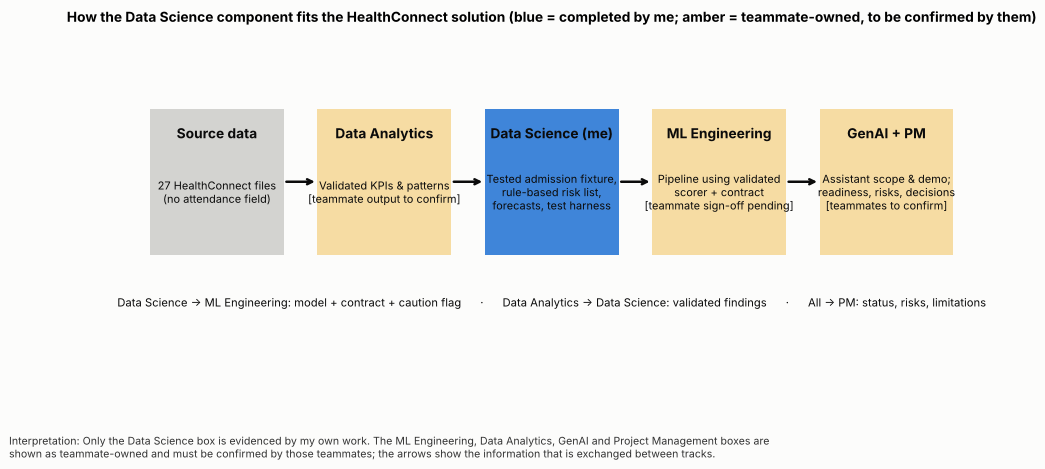

In [9]:
fig, ax = plt.subplots(figsize=(12, 5)); ax.axis("off"); ax.grid(False)
boxes = [(0.02, "Source data", "27 HealthConnect files\n(no attendance field)", MUTED, "Input"), (0.22, "Data Analytics", "Validated KPIs & patterns\n[teammate output to confirm]", C[3], "Teammate"),
         (0.42, "Data Science (me)", "Tested admission fixture,\nrule-based risk list,\nforecasts, test harness", C[0], "Done"), (0.62, "ML Engineering", "Pipeline using validated\nscorer + contract\n[teammate sign-off pending]", C[3], "Teammate"),
         (0.82, "GenAI + PM", "Assistant scope & demo;\nreadiness, risks, decisions\n[teammates to confirm]", C[3], "Teammate")]
for x, t, s, col, tag in boxes:
    ax.add_patch(plt.Rectangle((x, .35), .16, .42, fc=col, ec="none", alpha=.9 if tag == "Done" else .35, transform=ax.transAxes))
    ax.text(x + .08, .70, t, ha="center", va="center", fontsize=11, fontweight="bold", color=INK, transform=ax.transAxes)
    ax.text(x + .08, .53, s, ha="center", va="center", fontsize=8.8, color=INK, transform=ax.transAxes)
for x in (.18, .38, .58, .78): ax.annotate("", xy=(x + .04, .56), xytext=(x, .56), arrowprops=dict(arrowstyle="->", lw=2, color=INK), xycoords="axes fraction")
ax.text(.5, .2, "Data Science → ML Engineering: model + contract + caution flag      ·      Data Analytics → Data Science: validated findings      ·      All → PM: status, risks, limitations", ha="center", fontsize=9, color=INK, transform=ax.transAxes)
ax.set_title("How the Data Science component fits the HealthConnect solution (blue = completed by me; amber = teammate-owned, to be confirmed by them)", fontsize=11)
save_fig(fig, "w8_02_integration_view", "Only the Data Science box is evidenced by my own work. The ML Engineering, Data Analytics, GenAI and Project Management boxes are shown as teammate-owned and must be confirmed by those teammates; the arrows show the information that is exchanged between tracks.", "Data Science component in the integrated solution")
plt.show()

In [10]:
R["review"] = REV.to_dict("records"); R["options"] = OPT.to_dict("records"); R["final"] = FINAL.round(4).to_dict("records"); R["errors"] = ERRS.to_dict("records"); R["strength_weak"] = SW.to_dict("records")
R["decisions"] = DEC.to_dict("records"); R["use"] = USE.to_dict("records"); R["integration"] = INT.to_dict("records")
print("Final model:", "Week 6 candidate (logistic regression), unchanged — integration fixture, not approved for patient-level decisions")
USE[["Possible use", "Allowed?"]]

Final model: Week 6 candidate (logistic regression), unchanged — integration fixture, not approved for patient-level decisions


,Possible use,Allowed?
0,Rank patients by admission risk for clinical decisions,NO
1,Show a risk percentage to staff or patients,NO
2,Predict missed appointments / no-shows,NO
3,"Rank facilities, departments or doctors",NO
4,"Test the ML pipeline end to end (inputs, outputs, errors, persistence)",YES
5,Reuse the testing harness on an attendance model,YES
6,"Targeted outreach by a transparent rule (65+/50–64 with chronic disease, obesity or underweight)","YES (rule, not model)"
7,Plan appointment slots with the 2027 visit forecast,YES (as a flat baseline)
